In [ ]:
# Library
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from google.colab import drive
from torch.utils.data import ConcatDataset, DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
DCGAN_LATENT_DIM = 100
DCGAN_LR = 0.0002
DCGAN_BETAS = (0.5, 0.999)
DCGAN_EPOCHS = 20

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [1]:
# CP
from pathlib import Path

USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/Model_Comparison"
    )
else:
    PROJECT_DIR = Path(".")

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "dcgan"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Use Google Drive:", USE_GOOGLE_DRIVE)
print("Project Directory:", PROJECT_DIR)
print("Checkpoint Directory:", CHECKPOINT_DIR)
print("Output Directory:", OUTPUT_DIR)


Mounted at /content/drive
Use Google Drive: True
Project Directory: /content/drive/MyDrive/Model_Comparison
Checkpoint Directory: /content/drive/MyDrive/Model_Comparison/checkpoints
Output Directory: /content/drive/MyDrive/Model_Comparison/outputs/dcgan


In [ ]:
# Dataset
transform = transforms.ToTensor()

train_original = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_original = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

full_dataset = ConcatDataset([
    train_original,
    test_original
])

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [56000, 7000, 7000],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Total Dataset:", len(full_dataset))
print("Training Set:", len(train_dataset))
print("Validation Set:", len(val_dataset))
print("Testing Set:", len(test_dataset))


100%|██████████| 26.4M/26.4M [00:00<00:00, 118MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 3.80MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 49.7MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.18MB/s]

Total Dataset: 70000
Training Set: 56000
Validation Set: 7000
Testing Set: 7000


In [ ]:
# DCGAN -> Architecture

class DCGenerator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()

        self.latent_dim = latent_dim

        self.model = nn.Sequential(
            nn.ConvTranspose2d(
                latent_dim, 128,
                kernel_size=7,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                128, 64,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                64, 1,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.Sigmoid()
        )

    def forward(self, z):
        z = z.view(-1, self.latent_dim, 1, 1)
        return self.model(z)


class DCDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Conv2d(
                1, 64,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                64, 128,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                128, 1,
                kernel_size=7,
                stride=1,
                padding=0
            )
        )

    def forward(self, x):
        output = self.model(x)
        return output.view(-1, 1)


dc_generator = DCGenerator(
    DCGAN_LATENT_DIM
).to(DEVICE)

dc_discriminator = DCDiscriminator().to(DEVICE)

print("DCGAN GENERATOR")
print(dc_generator)

print("\nDCGAN DISCRIMINATOR")
print(dc_discriminator)


DCGAN GENERATOR
DCGenerator(
  (model): Sequential(
    (0): ConvTranspose2d(100, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): Sigmoid()
  )
)

DCGAN DISCRIMINATOR
DCDiscriminator(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyR

In [ ]:
# Optimizer

def weights_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight.data, 0.0, 0.02)

    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


dc_generator.apply(weights_init)
dc_discriminator.apply(weights_init)

dcgan_criterion = nn.BCEWithLogitsLoss()

optimizer_dc_G = optim.Adam(
    dc_generator.parameters(),
    lr=DCGAN_LR,
    betas=DCGAN_BETAS
)

optimizer_dc_D = optim.Adam(
    dc_discriminator.parameters(),
    lr=DCGAN_LR,
    betas=DCGAN_BETAS
)

print("DCGAN Learning Rate:", DCGAN_LR)
print("DCGAN Betas:", DCGAN_BETAS)
print("Weight Initialization: Normal(0, 0.02)")


DCGAN Learning Rate: 0.0002
DCGAN Betas: (0.5, 0.999)
Weight Initialization: Normal(0, 0.02)


In [ ]:
# Training

dc_g_losses = []
dc_d_losses = []
dc_epoch_times = []

dc_fixed_noise = torch.randn(
    16,
    DCGAN_LATENT_DIM,
    device=DEVICE
)

for epoch in range(DCGAN_EPOCHS):

    start_time = time.perf_counter()

    dc_generator.train()
    dc_discriminator.train()

    total_g_loss = 0.0
    total_d_loss = 0.0

    for images, _ in train_loader:

        images = images.to(DEVICE)
        batch_size = images.size(0)

        real_labels = torch.ones(
            batch_size, 1, device=DEVICE
        )

        fake_labels = torch.zeros(
            batch_size, 1, device=DEVICE
        )

        # Discriminator Training

        optimizer_dc_D.zero_grad()

        real_output = dc_discriminator(images)

        d_real_loss = dcgan_criterion(
            real_output,
            real_labels
        )

        noise = torch.randn(
            batch_size,
            DCGAN_LATENT_DIM,
            device=DEVICE
        )

        fake_images = dc_generator(noise)

        fake_output = dc_discriminator(
            fake_images.detach()
        )

        d_fake_loss = dcgan_criterion(
            fake_output,
            fake_labels
        )

        d_loss = (
            d_real_loss + d_fake_loss
        ) / 2

        d_loss.backward()
        optimizer_dc_D.step()

        # Generator Training

        optimizer_dc_G.zero_grad()

        for param in dc_discriminator.parameters():
            param.requires_grad_(False)

        noise = torch.randn(
            batch_size,
            DCGAN_LATENT_DIM,
            device=DEVICE
        )

        generated_images = dc_generator(noise)

        output = dc_discriminator(generated_images)

        g_loss = dcgan_criterion(
            output,
            real_labels
        )

        g_loss.backward()
        optimizer_dc_G.step()

        for param in dc_discriminator.parameters():
            param.requires_grad_(True)

        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    avg_d_loss = total_d_loss / len(train_loader)
    avg_g_loss = total_g_loss / len(train_loader)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - start_time

    dc_d_losses.append(avg_d_loss)
    dc_g_losses.append(avg_g_loss)
    dc_epoch_times.append(epoch_time)

    print(
        f"Epoch [{epoch+1}/{DCGAN_EPOCHS}] | "
        f"D Loss: {avg_d_loss:.4f} | "
        f"G Loss: {avg_g_loss:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

print("\nDCGAN Training Complete!")
print(f"Average Epoch Time: {np.mean(dc_epoch_times):.2f}s")


generator_path = CHECKPOINT_DIR / "dcgan_generator.pt"
discriminator_path = CHECKPOINT_DIR / "dcgan_discriminator.pt"

torch.save(
    {
        key: value.detach().cpu().clone()
        for key, value in dc_generator.state_dict().items()
    },
    generator_path
)

torch.save(
    {
        key: value.detach().cpu().clone()
        for key, value in dc_discriminator.state_dict().items()
    },
    discriminator_path
)

print("Saved generator:", generator_path)
print("Saved discriminator:", discriminator_path)


pd.DataFrame({
    "epoch": range(1, DCGAN_EPOCHS + 1),
    "generator_loss": dc_g_losses,
    "discriminator_loss": dc_d_losses,
    "epoch_time_s": dc_epoch_times
}).to_csv(
    OUTPUT_DIR / "loss_history.csv",
    index=False
)

pd.DataFrame([{
    "model": "DCGAN",
    "latent_dim": DCGAN_LATENT_DIM,
    "learning_rate": DCGAN_LR,
    "epochs": DCGAN_EPOCHS,
    "seed": SEED,
    "final_generator_loss": dc_g_losses[-1],
    "final_discriminator_loss": dc_d_losses[-1],
    "mean_epoch_time_s": float(np.mean(dc_epoch_times))
}]).to_csv(
    OUTPUT_DIR / "training_summary.csv",
    index=False
)


Epoch [1/20] | D Loss: 0.1792 | G Loss: 2.8195 | Time: 17.92s
Epoch [2/20] | D Loss: 0.2599 | G Loss: 2.0851 | Time: 15.43s
Epoch [3/20] | D Loss: 0.3204 | G Loss: 1.7877 | Time: 15.35s
Epoch [4/20] | D Loss: 0.3641 | G Loss: 1.6272 | Time: 14.20s
Epoch [5/20] | D Loss: 0.3950 | G Loss: 1.5325 | Time: 14.33s
Epoch [6/20] | D Loss: 0.4077 | G Loss: 1.4871 | Time: 13.76s
Epoch [7/20] | D Loss: 0.4252 | G Loss: 1.4489 | Time: 13.95s
Epoch [8/20] | D Loss: 0.4408 | G Loss: 1.4061 | Time: 13.91s
Epoch [9/20] | D Loss: 0.4492 | G Loss: 1.3682 | Time: 13.82s
Epoch [10/20] | D Loss: 0.4678 | G Loss: 1.3365 | Time: 13.75s
Epoch [11/20] | D Loss: 0.4797 | G Loss: 1.3048 | Time: 13.73s
Epoch [12/20] | D Loss: 0.4894 | G Loss: 1.2832 | Time: 13.75s
Epoch [13/20] | D Loss: 0.4994 | G Loss: 1.2636 | Time: 13.73s
Epoch [14/20] | D Loss: 0.5036 | G Loss: 1.2395 | Time: 13.76s
Epoch [15/20] | D Loss: 0.5098 | G Loss: 1.2350 | Time: 14.36s
Epoch [16/20] | D Loss: 0.5145 | G Loss: 1.2163 | Time: 13.84s
E

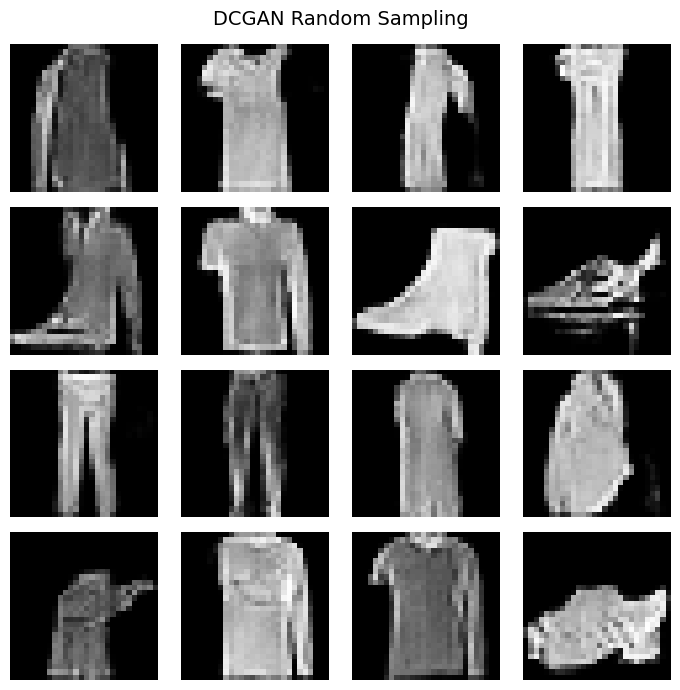

Saved image to: /content/drive/MyDrive/Model_Comparison/outputs/dcgan/random_sampling.png


In [ ]:
# Random Sampling

dc_generator.eval()

with torch.no_grad():
    generated_images = dc_generator(dc_fixed_noise)

fig, axes = plt.subplots(
    4, 4,
    figsize=(7, 7)
)

for i, ax in enumerate(axes.flat):

    image = (
        generated_images[i, 0]
        .detach()
        .cpu()
        .numpy()
    )

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.axis("off")

fig.suptitle(
    "DCGAN Random Sampling",
    fontsize=14
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "random_sampling.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved image to:", OUTPUT_DIR / "random_sampling.png")


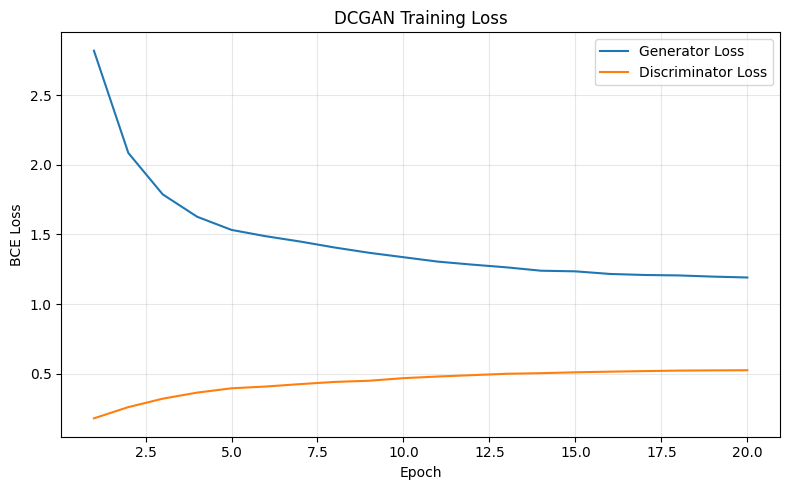

Saved image to: /content/drive/MyDrive/Model_Comparison/outputs/dcgan/training_loss.png


In [ ]:

# Training Loss

fig, ax = plt.subplots(figsize=(8, 5))

epochs = range(1, DCGAN_EPOCHS + 1)

ax.plot(
    epochs,
    dc_g_losses,
    label="Generator Loss"
)

ax.plot(
    epochs,
    dc_d_losses,
    label="Discriminator Loss"
)

ax.set_title("DCGAN Training Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("BCE Loss")

ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved image to:", OUTPUT_DIR / "training_loss.png")
